# 02 · EDA Baseline — OASIS-2

## Pregunta de investigación

**¿Qué diferencias existen en la visita inicial entre los pacientes Nondemented, Demented y aquellos clasificados como Converted durante el seguimiento?**

El objetivo de este notebook es estudiar las características basales de los tres grupos antes de construir modelos de Machine Learning.

> **Privacidad y uso de datos:** el dataset original OASIS-2 no se distribuye con este repositorio. Se conservan únicamente código, estadísticas agregadas y visualizaciones derivadas. Se han eliminado registros individuales e identificadores de participantes.


## Guía de variables

Antes de comenzar el análisis, conviene entender qué representa cada variable. OASIS-2 combina información demográfica, cognitiva y medidas obtenidas a partir de resonancia magnética (MRI).

| Variable | ¿Qué significa? | Interpretación sencilla |
|---|---|---|
| `Group` | Grupo clínico/longitudinal | `Nondemented`: sin demencia durante el seguimiento; `Demented`: demencia; `Converted`: sujetos inicialmente sin demencia que pasan a ser clasificados con demencia durante el seguimiento. |
| `Visit` | Número de visita | Indica si se trata de la primera, segunda, tercera... evaluación del sujeto. |
| `MR Delay` | Tiempo desde la primera visita | Número de días transcurridos desde la visita inicial. |
| `M/F` | Sexo | Sexo registrado en el dataset. |
| `Age` | Edad | Edad del participante, en años. |
| `EDUC` | Educación | Años de educación formal. Puede utilizarse como una aproximación parcial a la reserva cognitiva. |
| `SES` | Socioeconomic Status | Nivel socioeconómico codificado de 1 a 5; valores más bajos representan un nivel socioeconómico más alto. |
| `MMSE` | Mini-Mental State Examination | Test breve de función cognitiva, con puntuación de 0 a 30. En general, una puntuación mayor indica mejor rendimiento cognitivo. No diagnostica por sí solo una demencia. |
| `CDR` | Clinical Dementia Rating | Escala clínica utilizada para valorar la gravedad de la demencia. En términos generales: 0 = sin demencia, 0.5 = deterioro muy leve/cuestionable, 1 = leve, 2 = moderada y 3 = grave. |
| `eTIV` | Estimated Total Intracranial Volume | Estimación del volumen total contenido dentro del cráneo. Ayuda a tener en cuenta que las personas tienen tamaños craneales diferentes. |
| `nWBV` | Normalized Whole Brain Volume | Volumen cerebral total normalizado respecto al tamaño intracraneal. Valores menores pueden reflejar una menor proporción de tejido cerebral, aunque no constituyen por sí solos un diagnóstico. |
| `ASF` | Atlas Scaling Factor | Factor utilizado durante el procesamiento de MRI para ajustar el cerebro de cada participante a un atlas de referencia. Está matemáticamente muy relacionado con eTIV. |

Estas variables deben interpretarse conjuntamente y dentro del contexto clínico. **Ninguna de ellas, de forma aislada, equivale a un diagnóstico de Alzheimer.**


## 1. Preparación del entorno y selección de la cohorte baseline

OASIS-2 contiene múltiples visitas por sujeto. Para estudiar las diferencias existentes al inicio del seguimiento se selecciona únicamente `Visit = 1`, obteniendo una observación por paciente.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats import f_oneway
from scipy.stats import levene
from scipy.stats import shapiro
from scipy.stats import kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [3]:
df_oasis2 = pd.read_excel("../data/oasis_2.xlsx")

In [5]:
df_baseline= df_oasis2[df_oasis2['Visit'] == 1]

In [7]:
df_baseline.shape

(150, 15)

In [9]:
df_baseline['Group'].value_counts()

Group
Nondemented    72
Demented       64
Converted      14
Name: count, dtype: int64

La cohorte baseline contiene **150 pacientes**: 72 Nondemented, 64 Demented y 14 Converted.

`Converted` debe interpretarse como una **etiqueta de trayectoria del sujeto durante el seguimiento**, no simplemente como su estado clínico en la primera visita. Esta distinción será especialmente importante al formular posteriormente la pregunta predictiva.


## 2. Edad

### ¿Existen diferencias de edad entre los tres grupos en la visita inicial?

Se comparan primero las distribuciones de edad. Después se comprueban los supuestos de normalidad y homogeneidad de varianzas para seleccionar el contraste estadístico apropiado.


In [11]:
df_baseline.groupby('Group')['Age'].agg(['mean','median', 'std', ])

,mean,median,std
Group,,,
Converted,77.071429,78.5,7.690797
Demented,75.109375,75.0,6.735637
Nondemented,75.430556,75.0,8.232239


<Axes: xlabel='Group', ylabel='Age'>

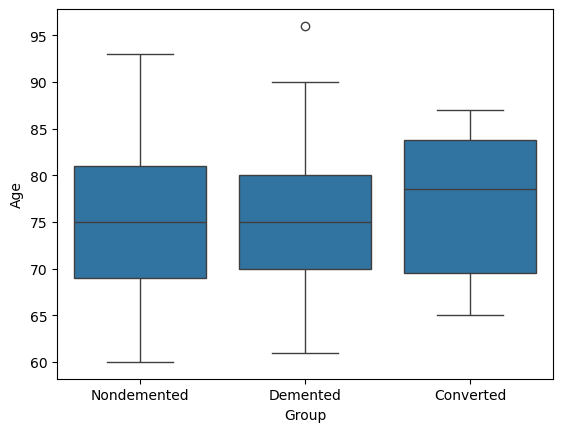

In [13]:
sns.boxplot(
    data=df_baseline,
    x='Group',
    y='Age'
)

In [15]:
age_converted = df_baseline[
    df_baseline['Group']=='Converted']['Age']

In [17]:
age_nondemented = df_baseline[
    df_baseline['Group']=='Nondemented']['Age']

In [19]:
age_demented = df_baseline[
    df_baseline['Group']=='Demented']['Age']

In [21]:
shapiro(age_converted)

ShapiroResult(statistic=0.9112752674704138, pvalue=0.16444964030717651)

In [23]:
shapiro(age_nondemented)

ShapiroResult(statistic=0.9768646171820197, pvalue=0.20616353048927383)

In [25]:
shapiro(age_demented)

ShapiroResult(statistic=0.9835579238664588, pvalue=0.5520635807783737)

In [27]:
levene(age_converted, age_nondemented, age_demented)

LeveneResult(statistic=1.5869872656438946, pvalue=0.20802498006281162)

In [29]:
f_oneway(age_converted, age_nondemented, age_demented)

F_onewayResult(statistic=0.38547284087534267, pvalue=0.6808144005544063)

**Interpretación.** El grupo Converted presentó una edad media ligeramente superior (77,1 años) respecto a Nondemented (75,4) y Demented (75,1). Sin embargo, el ANOVA no mostró diferencias estadísticamente significativas entre los grupos (F = 0,385; p = 0,681). En esta muestra no encontramos evidencia de diferencias en la edad media basal.


## 3. Sexo

Para estudiar si la distribución por sexo difiere entre los grupos se construye una tabla de contingencia y se aplica una prueba χ² de independencia.


In [31]:
tabla_sex= pd.crosstab(
    df_baseline['Group'],
    df_baseline['M/F']
)

In [33]:
tabla_sex

M/F,F,M
Group,,
Converted,10,4
Demented,28,36
Nondemented,50,22


In [35]:
sex_porcentajes= pd.crosstab(                      #crea tabla con proporciones
                        df_baseline['Group'],
                        df_baseline['M/F'],
                        normalize='index'
                ) * 100                        #convierte las proporciones en porcentajes

In [37]:
sex_porcentajes.round(1)

M/F,F,M
Group,,
Converted,71.4,28.6
Demented,43.8,56.2
Nondemented,69.4,30.6


In [39]:
chi2_contingency(tabla_sex)

Chi2ContingencyResult(statistic=10.261965856723922, pvalue=0.005910747775787819, dof=2, expected_freq=array([[ 8.21333333,  5.78666667],
       [37.54666667, 26.45333333],
       [42.24      , 29.76      ]]))

**Interpretación.** La prueba χ² mostró evidencia de asociación entre sexo y grupo en esta cohorte (p = 0,0059). Este resultado describe una asociación dentro de OASIS-2 y **no debe interpretarse como una relación causal ni como una estimación del riesgo poblacional de demencia**.


## 4. MMSE basal

### ¿Qué es MMSE?

El **MMSE (Mini-Mental State Examination)** es una prueba breve utilizada para evaluar distintas funciones cognitivas, como orientación, memoria, atención, cálculo y lenguaje. Su puntuación total va de **0 a 30 puntos** y, de forma general, puntuaciones más altas indican un mejor rendimiento cognitivo.

Es importante no interpretar MMSE como un diagnóstico automático: una puntuación determinada no permite afirmar por sí sola que una persona tenga o no demencia. La edad, la educación y otros factores pueden influir en el resultado, y la valoración clínica requiere información adicional.

En este análisis se estudia si los valores de MMSE en la **primera visita** difieren entre Nondemented, Demented y Converted y, especialmente, si permiten distinguir a quienes posteriormente convertirán de quienes permanecerán Nondemented.


In [41]:
df_baseline.groupby('Group')['MMSE'].agg(['mean','median', 'std', ])

,mean,median,std
Group,,,
Converted,29.357143,30.0,0.928783
Demented,25.328125,26.0,3.319278
Nondemented,29.194444,29.0,0.849837


<Axes: xlabel='Group', ylabel='MMSE'>

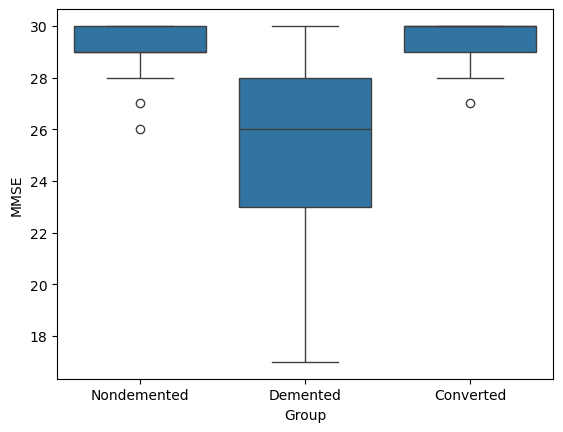

In [43]:
sns.boxplot(
    data=df_baseline,
    x='Group',
    y='MMSE'
)

In [45]:
mmse_converted= df_baseline[
    df_baseline['Group']=='Converted']['MMSE']

In [47]:
mmse_nondemented= df_baseline[
    df_baseline['Group']=='Nondemented']['MMSE']

In [49]:
mmse_demented= df_baseline[
    df_baseline['Group']=='Demented']['MMSE']

In [51]:
shapiro(mmse_converted)

ShapiroResult(statistic=0.730432376920239, pvalue=0.0007777328981660972)

In [53]:
shapiro(mmse_demented)

ShapiroResult(statistic=0.9487875750669076, pvalue=0.009978320729671218)

In [55]:
shapiro(mmse_nondemented)

ShapiroResult(statistic=0.7982507761756514, pvalue=1.5398238552822035e-08)

In [57]:
kruskal(mmse_nondemented,mmse_demented, mmse_converted)

KruskalResult(statistic=61.78964589981626, pvalue=3.824272878212958e-14)

In [59]:
mannwhitneyu(mmse_nondemented, mmse_converted)

MannwhitneyuResult(statistic=433.0, pvalue=0.3723494043637404)

In [61]:
mannwhitneyu(mmse_nondemented, mmse_demented)

MannwhitneyuResult(statistic=3976.0, pvalue=9.962665804321837e-14)

In [63]:
mannwhitneyu(mmse_converted, mmse_demented)

MannwhitneyuResult(statistic=789.0, pvalue=7.872011130497296e-06)

In [65]:
alpha = 0.05
n_comparaciones = 3

alpha_bonferroni = alpha / n_comparaciones

print(alpha_bonferroni)

0.016666666666666666


**Interpretación.** Kruskal-Wallis mostró diferencias globales entre los tres grupos (H = 61,79; p < 0,001). Tras las comparaciones post-hoc con Mann–Whitney y corrección de Bonferroni (α = 0,0167), Demented difirió de Nondemented y de Converted, mientras que **Converted y Nondemented no mostraron diferencias significativas** (p = 0,372).

Por tanto, MMSE distingue principalmente a quienes ya presentan demencia, pero en esta cohorte no separa claramente en baseline a quienes posteriormente convertirán de quienes permanecerán Nondemented.


## 5. nWBV basal

### ¿Qué es nWBV?

`nWBV` significa **Normalized Whole Brain Volume** o volumen cerebral total normalizado. Es una medida obtenida a partir de MRI que expresa el volumen cerebral teniendo en cuenta el tamaño intracraneal de la persona.

La normalización es importante porque dos personas pueden tener cerebros y cráneos de tamaños diferentes sin que esa diferencia implique enfermedad. En términos generales, un menor nWBV puede estar relacionado con una menor cantidad relativa de tejido cerebral, pero **no diagnostica Alzheimer ni demencia por sí solo**.

Aquí analizamos si existen diferencias de nWBV entre los grupos en la primera visita y si esta medida estructural aporta alguna señal relacionada con la futura conversión.


In [67]:
df_baseline.groupby('Group')['nWBV'].agg(['mean','median', 'std', ])

,mean,median,std
Group,,,
Converted,0.737860,0.729944,0.033016
Demented,0.724357,0.726013,0.031476
Nondemented,0.746062,0.746976,0.038655


<Axes: xlabel='Group', ylabel='nWBV'>

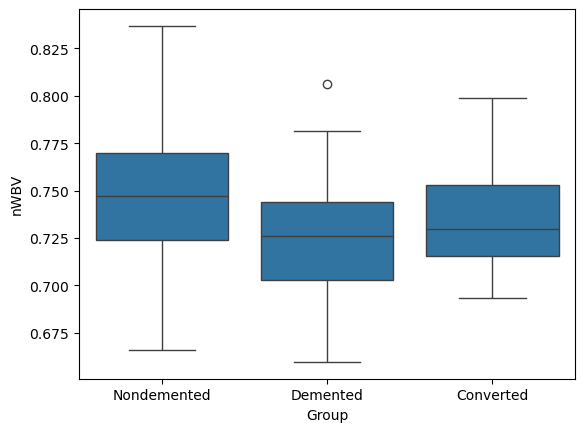

In [69]:
sns.boxplot(
    data=df_baseline,
    x='Group',
    y='nWBV'
)

In [71]:
nWBV_converted= df_baseline[
    df_baseline['Group']=='Converted']['nWBV']

In [73]:
nWBV_demented= df_baseline[
    df_baseline['Group']=='Demented']['nWBV']

In [75]:
nWBV_nondemented= df_baseline[
    df_baseline['Group']=='Nondemented']['nWBV']

In [77]:
nondemented= shapiro(nWBV_nondemented)
demented = shapiro(nWBV_demented)
converted = shapiro(nWBV_converted)

In [79]:
nondemented

ShapiroResult(statistic=0.9888269937899163, pvalue=0.7780297866013317)

In [81]:
demented

ShapiroResult(statistic=0.9919040054857404, pvalue=0.9519100676680882)

In [83]:
converted

ShapiroResult(statistic=0.9326539897639876, pvalue=0.33230120797163243)

In [85]:
levene(nWBV_converted, nWBV_nondemented, nWBV_demented)

LeveneResult(statistic=1.0267889685064668, pvalue=0.3607092693617743)

In [87]:
f_oneway(
    nWBV_nondemented,
    nWBV_demented,
    nWBV_converted
)

F_onewayResult(statistic=6.443137193759381, pvalue=0.0020782709339167062)

In [89]:
tukey_nWBV = pairwise_tukeyhsd(
    endog=df_baseline['nWBV'],
    groups=df_baseline['Group'],
    alpha=0.05
)
print(tukey_nWBV)


    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1     group2   meandiff p-adj   lower  upper  reject
-----------------------------------------------------------
Converted    Demented  -0.0135 0.3984 -0.0381 0.0111  False
Converted Nondemented   0.0082 0.7057 -0.0162 0.0326  False
 Demented Nondemented   0.0217 0.0013  0.0074  0.036   True
-----------------------------------------------------------


**Interpretación.** Se encontraron diferencias globales de nWBV entre los grupos (ANOVA, F = 6,44; p = 0,0021). El post-hoc de Tukey mostró diferencias entre Demented y Nondemented, pero no entre Converted y Nondemented ni entre Converted y Demented.

Descriptivamente, Converted presentó valores intermedios de nWBV. Sin embargo, nWBV por sí sola no proporciona una señal basal estadísticamente clara de futura conversión.


## 6. Educación (EDUC)

### ¿Por qué puede ser relevante la educación?

`EDUC` representa los **años de educación formal** del participante. En investigación sobre envejecimiento y demencia suele estudiarse en relación con el concepto de **reserva cognitiva**: la capacidad del cerebro para tolerar cambios asociados a la edad o a la enfermedad manteniendo durante más tiempo el funcionamiento cognitivo.

Esto no significa que una mayor educación proteja automáticamente frente a la demencia. EDUC es solo una aproximación parcial a un fenómeno mucho más complejo.

En este análisis se explora si los años de educación difieren entre los tres grupos y, especialmente, entre Converted y Nondemented.


In [91]:
df_baseline.groupby('Group')['EDUC'].agg(['mean','median', 'std', ])

,mean,median,std
Group,,,
Converted,15.142857,16.0,2.567763
Demented,13.687500,12.5,2.916156
Nondemented,15.166667,16.0,2.732177


<Axes: xlabel='Group', ylabel='EDUC'>

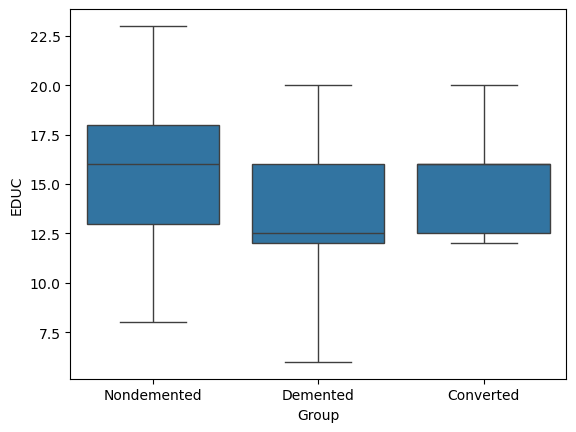

In [93]:
sns.boxplot(
    data=df_baseline,
    x='Group',
    y='EDUC'
)

In [95]:
EDUC_converted= df_baseline[
    df_baseline['Group']=='Converted']['EDUC']

In [97]:
EDUC_Nondemented= df_baseline[
    df_baseline['Group']=='Nondemented']['EDUC']

In [99]:
EDUC_Demented= df_baseline[
    df_baseline['Group']=='Demented']['EDUC']

In [101]:
kruskal(EDUC_converted, EDUC_Nondemented, EDUC_Demented)

KruskalResult(statistic=10.044719894758606, pvalue=0.006588958750822335)

In [103]:
mannwhitneyu(EDUC_converted, EDUC_Demented)

MannwhitneyuResult(statistic=578.0, pvalue=0.08083896784038108)

In [105]:
mannwhitneyu(EDUC_converted, EDUC_Nondemented)

MannwhitneyuResult(statistic=492.5, pvalue=0.8956145185222377)

In [107]:
mannwhitneyu(EDUC_Demented, EDUC_Nondemented)

MannwhitneyuResult(statistic=1617.0, pvalue=0.0022759733537818937)

**Interpretación.** En esta cohorte se observan diferencias de EDUC principalmente entre Demented y Nondemented. Sin embargo, EDUC por sí sola no muestra una diferencia basal clara entre Converted y Nondemented.


## 7. CDR basal

### ¿Qué es CDR?

El **CDR (Clinical Dementia Rating)** es una escala clínica utilizada para valorar la presencia y gravedad del deterioro asociado a la demencia. Considera diferentes áreas del funcionamiento cognitivo y cotidiano.

De forma simplificada, sus valores se interpretan como:

- **0:** sin demencia.
- **0.5:** deterioro muy leve o cuestionable.
- **1:** demencia leve.
- **2:** demencia moderada.
- **3:** demencia grave.

CDR es especialmente importante en este proyecto porque está **muy próximo a la propia definición clínica del estado de demencia**. Por eso puede separar muy bien a pacientes que ya presentan demencia, pero utilizarlo como predictor también puede introducir circularidad: el modelo podría estar aprendiendo parcialmente información que ya forma parte de la clasificación clínica que intentamos estudiar.

Por este motivo se explora aquí su distribución y posteriormente se compararán modelos con y sin CDR.


In [109]:
df_baseline.groupby('Group')['CDR'].agg(['mean','median', 'std', ])

,mean,median,std
Group,,,
Converted,0.035714,0.0,0.133631
Demented,0.601562,0.5,0.202753
Nondemented,0.000000,0.0,0.000000


<Axes: xlabel='Group', ylabel='CDR'>

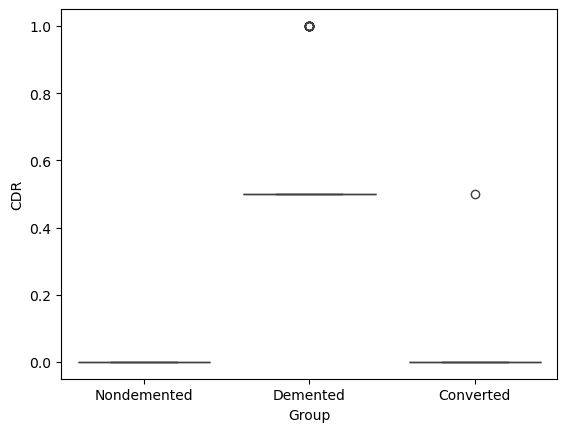

In [111]:
sns.boxplot(
    data=df_baseline,
    x='Group',
    y='CDR'
)

In [113]:
pd.crosstab(
    df_baseline['Group'],
    df_baseline['CDR']
)

CDR,0.0,0.5,1.0
Group,,,
Converted,13,1,0
Demented,0,51,13
Nondemented,72,0,0


**Interpretación.** CDR presenta una separación muy marcada entre Demented y Nondemented en baseline, mientras que Converted y Nondemented muestran valores muy similares.

Debido a su proximidad al estado clínico utilizado para caracterizar la demencia, su inclusión en Machine Learning podría producir una estimación excesivamente optimista del rendimiento. Por este motivo, posteriormente se evaluarán modelos **con y sin CDR**.


## 8. eTIV y ASF

### ¿Qué representan estas medidas de MRI?

`eTIV` (**Estimated Total Intracranial Volume**) es una estimación del volumen total dentro del cráneo. Es útil como referencia porque el tamaño de la cabeza varía naturalmente entre personas y esa variación debe tenerse en cuenta al comparar medidas cerebrales.

`ASF` (**Atlas Scaling Factor**) es un factor calculado durante el procesamiento de las imágenes para ajustar el cerebro de cada participante a un atlas cerebral de referencia. Está estrechamente relacionado con el tamaño intracraneal: cuanto mayor es el volumen intracraneal estimado, menor tiende a ser el factor de escalado necesario.

Por este motivo, eTIV y ASF pueden contener información prácticamente redundante. Analizar su correlación permite decidir si tiene sentido utilizar ambas variables simultáneamente en Machine Learning.


In [115]:
df_baseline.groupby('Group')['eTIV'].agg(['mean','median', 'std', ])

,mean,median,std
Group,,,
Converted,1438.430677,1405.436455,132.856874
Demented,1475.934604,1458.575000,173.583256
Nondemented,1480.065788,1457.470000,183.812878


<Axes: xlabel='Group', ylabel='eTIV'>

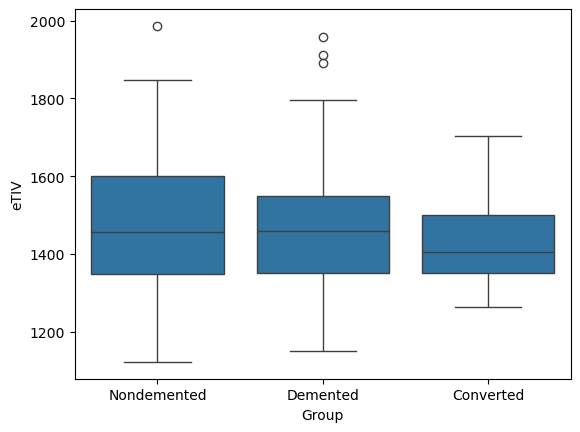

In [117]:
sns.boxplot(
    data=df_baseline,
    x='Group',
    y='eTIV'
)

In [119]:
eTIV_converted= df_baseline[
    df_baseline['Group']=='Converted']['eTIV']

In [121]:
eTIV_Nondemented= df_baseline[
    df_baseline['Group']=='Nondemented']['eTIV']

In [123]:
eTIV_Demented= df_baseline[
    df_baseline['Group']=='Demented']['eTIV']

In [125]:
nondemented= shapiro(eTIV_Nondemented)
demented = shapiro(eTIV_Demented)
converted = shapiro(eTIV_converted)

In [127]:
nondemented

ShapiroResult(statistic=0.9689903644064568, pvalue=0.07244116068283324)

In [129]:
demented 

ShapiroResult(statistic=0.9632140797452092, pvalue=0.05355386553915296)

In [131]:
converted

ShapiroResult(statistic=0.9351690991890779, pvalue=0.35993382054063167)

In [133]:
levene(eTIV_Nondemented, eTIV_Demented,eTIV_converted)

LeveneResult(statistic=0.9495648415063092, pvalue=0.389269516049632)

In [135]:
f_oneway(eTIV_Nondemented, eTIV_Demented,eTIV_converted)

F_onewayResult(statistic=0.3340833051480767, pvalue=0.7165363250303003)

**Interpretación.** No se encontraron diferencias estadísticamente significativas en eTIV basal entre Nondemented, Demented y Converted (ANOVA, F = 0,334; p = 0,717).


<Axes: xlabel='eTIV', ylabel='ASF'>

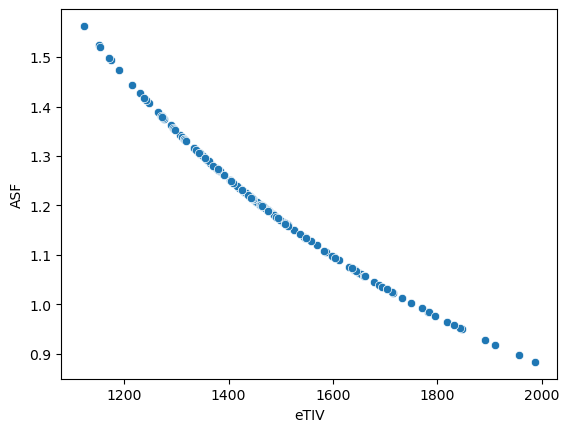

In [138]:
sns.scatterplot(
    data = df_baseline,
    x = 'eTIV',
    y = 'ASF'
)

In [140]:
df_baseline[['eTIV','ASF']].corr()

,eTIV,ASF
eTIV,1.000000,-0.988247
ASF,-0.988247,1.000000


eTIV y ASF presentan una correlación negativa extremadamente fuerte (Pearson r ≈ −0,988), indicando una elevada redundancia. Para evitar introducir información prácticamente duplicada, esta relación se tendrá en cuenta durante la selección de variables del modelo.


## 9. Nivel socioeconómico (SES)

### ¿Qué significa SES?

`SES` (**Socioeconomic Status**) representa el nivel socioeconómico mediante una escala ordinal de **1 a 5**. En la codificación utilizada en OASIS-2, **los valores más bajos corresponden a un nivel socioeconómico más alto**.

Por tanto, esta variable debe interpretarse con cuidado: un SES numéricamente mayor no significa una situación socioeconómica mejor, sino lo contrario.

Se explora su distribución porque factores sociales y educativos pueden relacionarse con el envejecimiento cognitivo, aunque una asociación observada en este dataset no implicaría causalidad.


In [142]:
df_baseline.groupby('Group')['SES'].agg(['mean','median', 'std', ])

,mean,median,std
Group,,,
Converted,1.857143,1.5,1.027105
Demented,2.750000,3.0,1.179368
Nondemented,2.416667,2.0,1.058167


<Axes: xlabel='Group', ylabel='SES'>

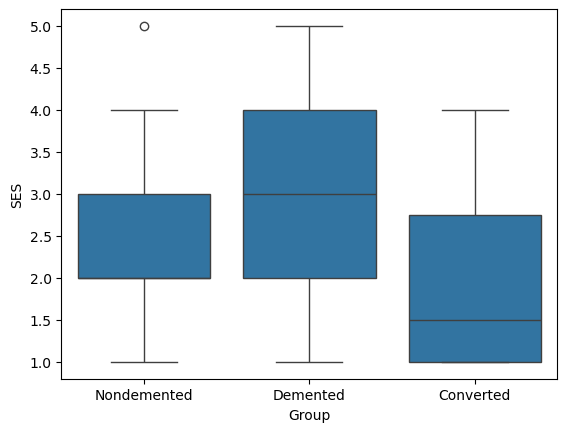

In [144]:
sns.boxplot(
    data=df_baseline,
    x='Group',
    y='SES'
)

**Interpretación.** SES no mostró diferencias claras entre los grupos. Aunque Demented presentó descriptivamente una media algo superior —que según la codificación corresponde a un nivel socioeconómico menor—, existe un amplio solapamiento entre las distribuciones. SES por sí sola no parece un discriminador fuerte.


## 10. Relaciones entre variables basales

Finalmente se examinan las correlaciones entre las principales variables numéricas. Se calculan tanto Pearson como Spearman para identificar relaciones relevantes y posibles redundancias antes del modelado.


In [146]:
df_baseline[['Age','EDUC','SES','MMSE','CDR','nWBV','eTIV', 'ASF']].corr()

,Age,EDUC,SES,MMSE,CDR,nWBV,eTIV,ASF
Age,1.000000,-0.065513,-0.016734,-0.022629,-0.039313,-0.558218,-0.009741,0.021186
EDUC,-0.065513,1.000000,-0.725770,0.216439,-0.227556,0.048269,0.236322,-0.218880
SES,-0.016734,-0.725770,1.000000,-0.180484,0.137950,0.027545,-0.244078,0.235332
MMSE,-0.022629,0.216439,-0.180484,1.000000,-0.691874,0.322168,-0.051675,0.059668
CDR,-0.039313,-0.227556,0.137950,-0.691874,1.000000,-0.310671,0.037690,-0.039806
nWBV,-0.558218,0.048269,0.027545,0.322168,-0.310671,1.000000,-0.194442,0.189497
eTIV,-0.009741,0.236322,-0.244078,-0.051675,0.037690,-0.194442,1.000000,-0.988247
ASF,0.021186,-0.218880,0.235332,0.059668,-0.039806,0.189497,-0.988247,1.000000


In [148]:
df_baseline[['Age','EDUC','SES','MMSE','CDR','nWBV','eTIV', 'ASF']].corr(method= 'spearman')

,Age,EDUC,SES,MMSE,CDR,nWBV,eTIV,ASF
Age,1.000000,-0.085020,-0.014618,-0.125723,-0.050511,-0.519670,0.003100,-0.003100
EDUC,-0.085020,1.000000,-0.722816,0.218558,-0.256270,0.052615,0.202313,-0.202313
SES,-0.014618,-0.722816,1.000000,-0.155127,0.154846,0.038605,-0.233269,0.233269
MMSE,-0.125723,0.218558,-0.155127,1.000000,-0.643701,0.293980,-0.101012,0.101012
CDR,-0.050511,-0.256270,0.154846,-0.643701,1.000000,-0.291162,0.024890,-0.024890
nWBV,-0.519670,0.052615,0.038605,0.293980,-0.291162,1.000000,-0.177140,0.177140
eTIV,0.003100,0.202313,-0.233269,-0.101012,0.024890,-0.177140,1.000000,-1.000000
ASF,-0.003100,-0.202313,0.233269,0.101012,-0.024890,0.177140,-1.000000,1.000000


| Relación | Pearson | Spearman | Lectura |
|---|---:|---:|---|
| EDUC – SES | −0,726 | **−0,723** | Fuerte negativa |
| MMSE – CDR | −0,692 | **−0,644** | Fuerte negativa |
| Age – nWBV | −0,558 | **−0,520** | Moderada-fuerte negativa |
| eTIV – ASF | −0,988 | **−1,000** | Prácticamente/perfectamente inversa |

Las relaciones más destacadas son:

- **eTIV–ASF:** redundancia prácticamente completa.
- **EDUC–SES:** asociación inversa fuerte, coherente con la codificación de SES.
- **MMSE–CDR:** relación inversa fuerte entre rendimiento cognitivo y gravedad clínica.
- **Age–nWBV:** asociación inversa moderada, compatible con menor volumen cerebral normalizado a mayor edad dentro de esta cohorte.

Estas asociaciones se interpretan como relaciones entre variables y no como relaciones causales.


# Conclusiones del EDA baseline

El análisis de la visita inicial muestra que varias variables permiten distinguir principalmente a los sujetos que **ya presentan demencia** de los Nondemented. Sin embargo, los futuros Converted presentan un importante solapamiento con Nondemented en variables como MMSE, EDUC y nWBV.

Además:

- la edad no mostró diferencias significativas entre los tres grupos;
- sexo mostró una asociación con `Group` dentro de esta cohorte;
- CDR está fuertemente relacionado con el estado clínico y requiere especial precaución como predictor;
- eTIV y ASF presentan una elevada redundancia.

En conjunto, **ninguna de las variables estudiadas individualmente separa claramente en baseline a Converted de Nondemented**. Esto motiva el siguiente paso del proyecto: evaluar si la combinación multivariable mediante modelos clásicos de Machine Learning puede detectar algún patrón basal asociado a la futura conversión.
